In [56]:
import numpy as np
import pickle
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from stwhmm_jax_optimized import STWHMM


sns.set_context("talk")

%matplotlib widget

In [57]:
observations = np.load("maze_clipped_spike_counts_pyr_only_Bilat_R02_20251106.npz")['observations']
time_bins = np.load("maze_clipped_spike_counts_pyr_only_Bilat_R02_20251106.npz")['time_bins']
print(observations.shape)
print(time_bins.shape)

(130600, 201)
(130600,)


Found 7 saved restarts
restart_00.pkl: log likelihood = -929457.225306
restart_01.pkl: log likelihood = -928452.684119
restart_02.pkl: log likelihood = -929753.669675
restart_03.pkl: log likelihood = -932700.090969
restart_04.pkl: log likelihood = -929415.858118
restart_05.pkl: log likelihood = -930676.686035
restart_06.pkl: log likelihood = -929256.300107


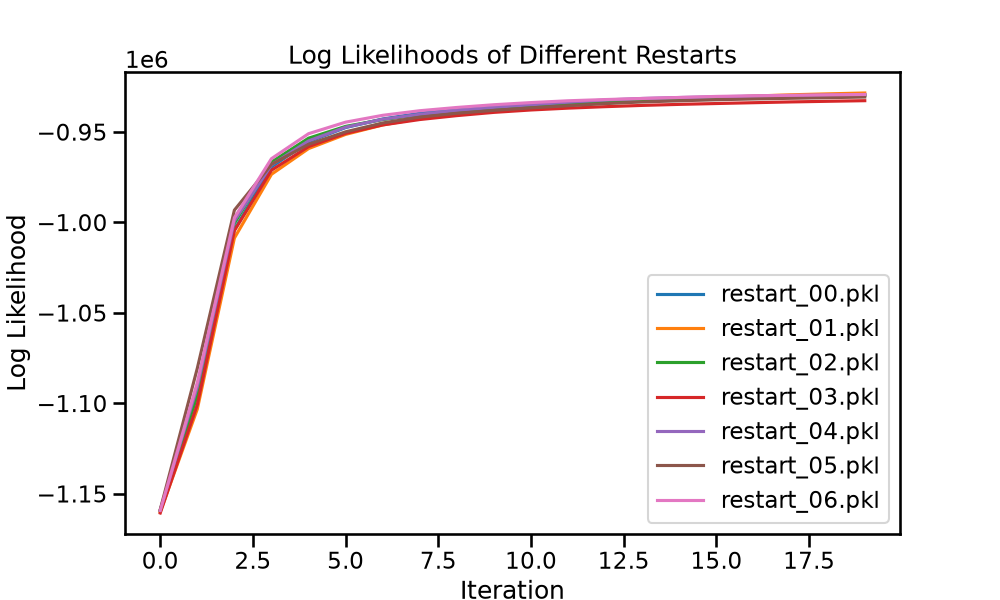

In [61]:
M = 101
S = 10
s = None


model = STWHMM(
    M=M,
    S=S,
    s=s,
    sequence_lengths=None,
    T_mask=None,
    H_mask=None,
    random_state=42,
    min_rate=1e-6
)

results_dir = Path("fit_results")

result_files = sorted(results_dir.glob("restart_*.pkl"))

print(f"Found {len(result_files)} saved restarts")


all_results = []

best_result = None
best_log_likelihood = -np.inf
best_file = None

plt.figure(figsize=(10, 6))

for file in result_files:

    # Load saved EMResult
    with open(file, "rb") as f:
        result = pickle.load(f)

    all_results.append(result)



    # find the likelhood
    log_likelihoods = result.log_likelihoods
    plt.plot(log_likelihoods, label=file.name)
    log_likelihood = log_likelihoods[-1]

    print(
        f"{file.name}: "
        f"log likelihood = {log_likelihood:.6f}"
    )

    # Check whether this is the best model
    if log_likelihood > best_log_likelihood:
        best_log_likelihood = log_likelihood
        best_result = result
        best_file = file


plt.xlabel("Iteration")
plt.legend()
plt.ylabel("Log Likelihood")
plt.title("Log Likelihoods of Different Restarts")
plt.show()

In [4]:
data = "fit_results/restart_00.pkl"
with open(data, "rb") as f:
    result = pickle.load(f)

print(result)

EMResult(log_likelihoods=array([-1159424.37870233, -1095348.05900917, -1004075.77548371,
        -969304.83778864,  -955390.43414316,  -947562.07653715,
        -942815.810375  ,  -939655.71997055,  -937393.2099043 ,
        -935705.22485984,  -934437.07582361,  -933449.59778009,
        -932705.98370733,  -932007.93001048,  -931436.43430373,
        -930971.98375144,  -930530.60198406,  -930146.36085516,
        -929756.18332661,  -929457.2253063 ]), losses=array([1159424.37870233, 1095348.05900917, 1004075.77548371,
        969304.83778864,  955390.43414316,  947562.07653715,
        942815.810375  ,  939655.71997055,  937393.2099043 ,
        935705.22485984,  934437.07582361,  933449.59778009,
        932705.98370733,  932007.93001048,  931436.43430373,
        930971.98375144,  930530.60198406,  930146.36085516,
        929756.18332661,  929457.2253063 ]), converged=False, n_iter=20, log_T=array([[       -inf, -0.24140771, -1.77351971, ..., -0.0685234 ,
        -0.1112412 , -1.517

In [59]:
model.restore(best_result)

print("\nBest model")
print(f"File: {best_file.name}")
print(f"Log likelihood: {best_log_likelihood:.6f}")


Best model
File: restart_01.pkl
Log likelihood: -928452.684119


In [12]:
state_sequence = model.viterbi(observations)

Z_hat = state_sequence[0]
tau_hat = state_sequence[1]

T_hat = model.T_
H_hat = model.H_
Lambda_hat = model.Lambda_

In [46]:
# find optimal sorting of the rows (neurons) of lambda_hat so that they peak in order
sort_order = np.argsort(np.argmax(Lambda_hat, axis=0))

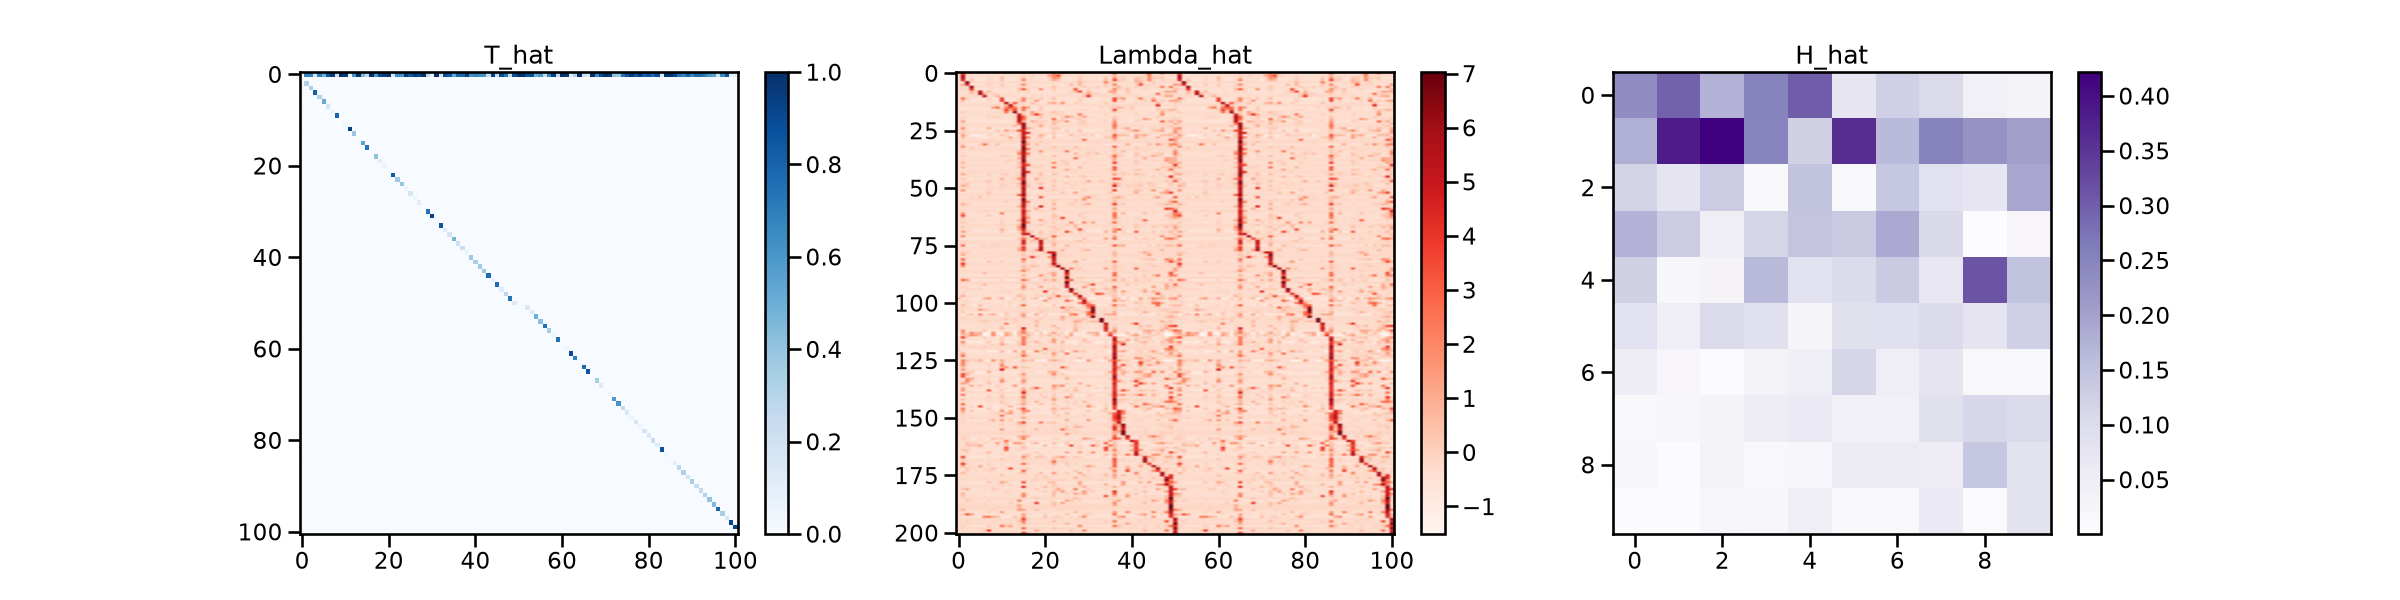

In [50]:
# plot the fitted matrices
plt.figure(figsize=(24, 6))
plt.subplot(1, 3, 1)
plt.imshow(T_hat, aspect='auto', cmap='Blues')
plt.colorbar()
plt.title('T_hat')

plt.subplot(1, 3, 2)
plt.imshow(stats.zscore(Lambda_hat[:, sort_order], axis=0).T, aspect='auto', cmap='Reds')
plt.colorbar()
plt.title('Lambda_hat')

plt.subplot(1, 3, 3)
plt.imshow(H_hat, aspect='auto', cmap='Purples')
plt.colorbar()
plt.title('H_hat')

plt.show()

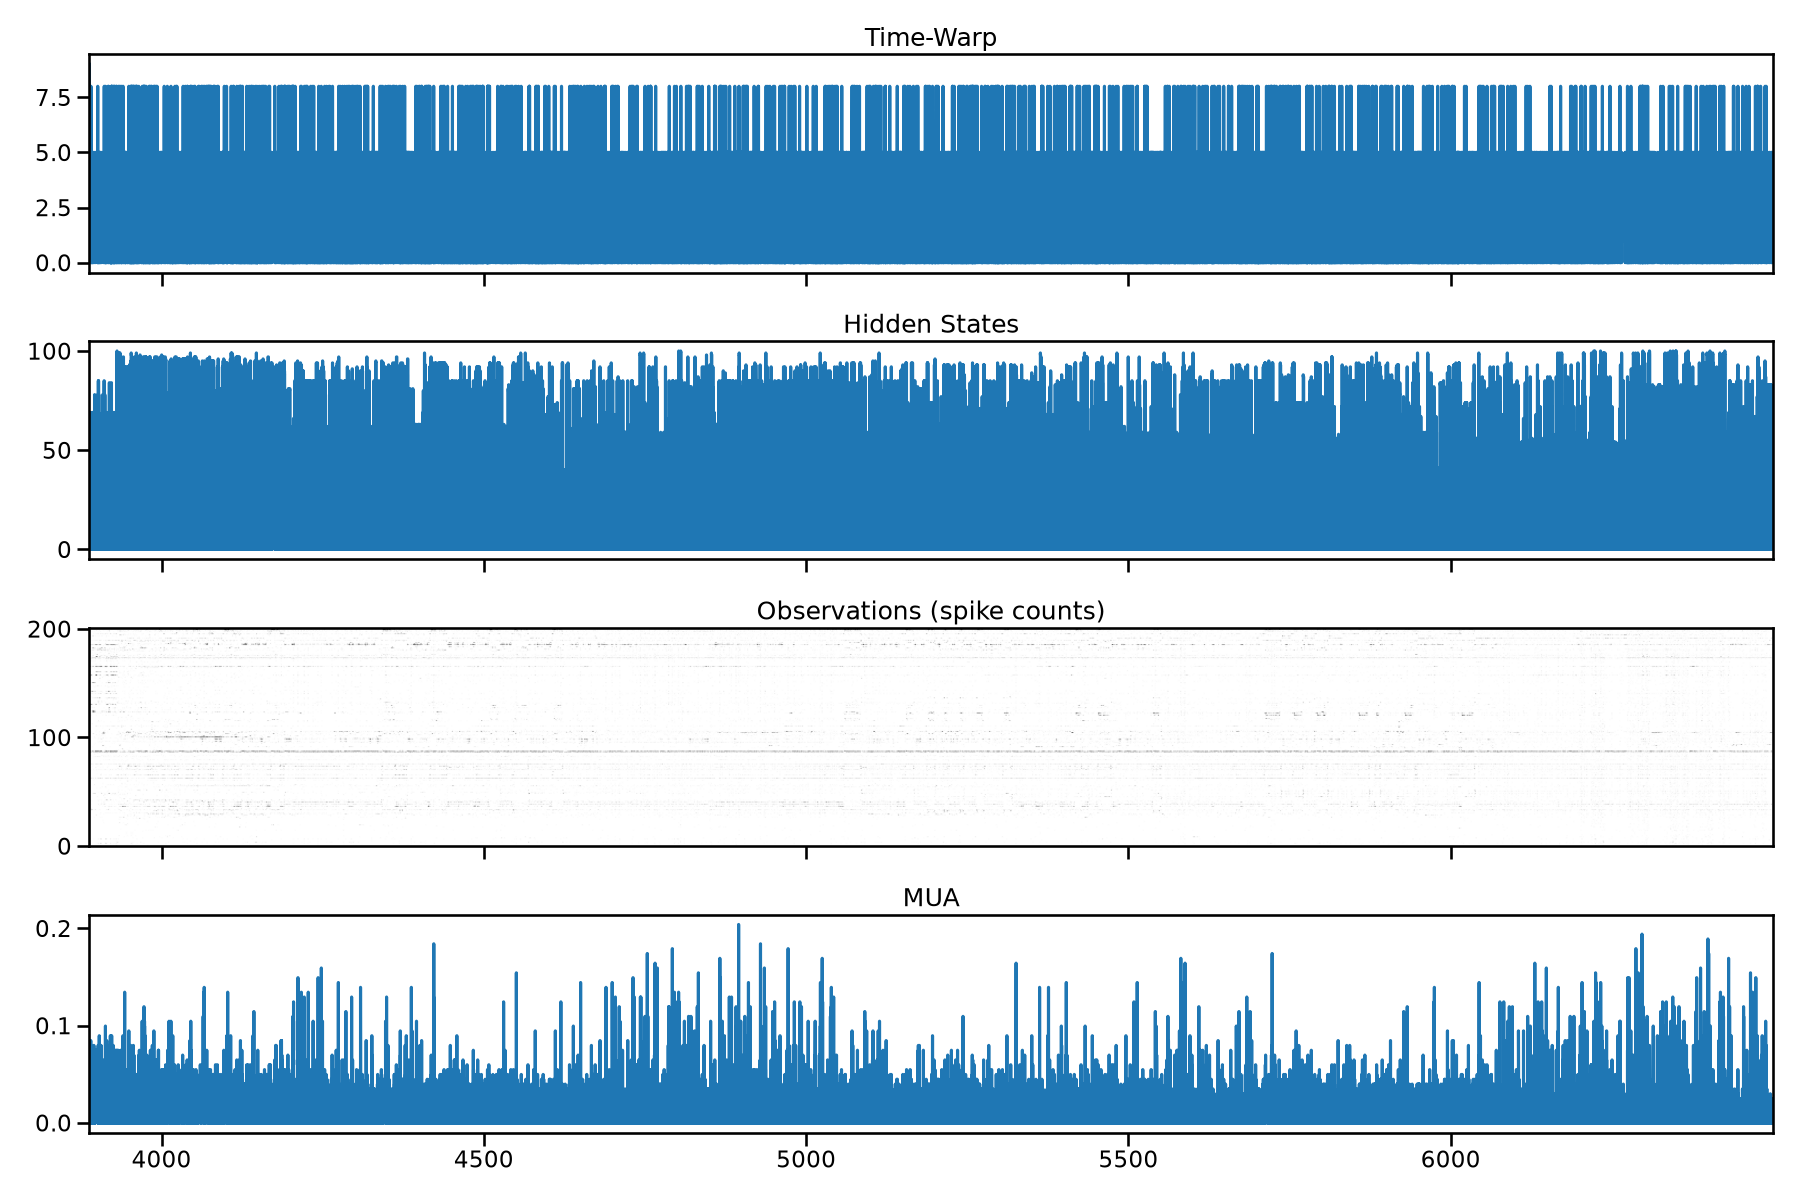

In [55]:



# plot the observations and the aligned hidden states and time-warps
fig, axs = plt.subplots(4, 1, figsize=(18, 12), sharex = True)
axs[0].plot(time_bins, state_sequence[1])
axs[0].set_title("Time-Warp")

axs[1].plot(time_bins, state_sequence[0])
axs[1].set_title("Hidden States")

axs[2].imshow(observations[:, sort_order].T, aspect='auto', cmap='Greys', vmin = 0, vmax = 1, extent=[time_bins[0], time_bins[-1], 0, observations.shape[1]])
axs[2].set_title("Observations (spike counts)")

axs[3].plot(time_bins, np.mean(observations, axis=1))
axs[3].set_title("MUA")

plt.tight_layout()
plt.show()